In [1]:
from pathlib import Path

import duckdb

RAW = Path("C:/dev/projects/first-analysis/data/raw")
DB = Path("C:/dev/projects/first-analysis/data/processed/olist.duckdb")

con = duckdb.connect(str(DB))

for csv in sorted(RAW.glob("*.csv")):
    table = csv.stem.replace("_dataset", "").replace("olist_", "")
    con.execute(
        f"CREATE OR REPLACE TABLE {table} AS "
        f"SELECT * FROM read_csv_auto('{csv.as_posix()}')"
    )
    print(table, con.execute(f"SELECT COUNT(*) FROM {table}").fetchone()[0])

customers 99441
geolocation 1000163
order_items 112650
order_payments 103886
order_reviews 99224
orders 99441
products 32951
sellers 3095
product_category_name_translation 71


In [2]:
print(con.execute("DESCRIBE orders").df()[["column_name", "column_type"]])

con.execute("""
    SELECT
        COUNT(*) AS total_orders,
        COUNT(*) - COUNT(order_approved_at) AS missing_approved,
        COUNT(*) - COUNT(order_delivered_carrier_date) AS missing_carrier_date,
        COUNT(*) - COUNT(order_delivered_customer_date) AS missing_delivered
    FROM orders
""").df()

                     column_name column_type
0                       order_id     VARCHAR
1                    customer_id     VARCHAR
2                   order_status     VARCHAR
3       order_purchase_timestamp   TIMESTAMP
4              order_approved_at   TIMESTAMP
5   order_delivered_carrier_date   TIMESTAMP
6  order_delivered_customer_date   TIMESTAMP
7  order_estimated_delivery_date   TIMESTAMP


,total_orders,missing_approved,missing_carrier_date,missing_delivered
0,99441,160,1783,2965


In [3]:
display(
    con.execute("""
SELECT order_status, COUNT(*) AS orders
FROM orders GROUP BY 1 ORDER BY 2 DESC
""").df()
)

con.execute("""
    SELECT
        (SELECT COUNT(*) - COUNT(DISTINCT order_id) FROM orders) AS dup_order_ids,
        (SELECT COUNT(*) - COUNT(DISTINCT review_id) FROM order_reviews) AS dup_review_ids,
        (SELECT COUNT(*) - COUNT(DISTINCT customer_id) FROM customers) AS dup_customer_ids
""").df()

,order_status,orders
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


,dup_order_ids,dup_review_ids,dup_customer_ids
0,0,814,0


In [4]:
con.execute("""
    SELECT
        order_status,
        COUNT(*) AS orders,
        COUNT(*) FILTER (WHERE order_delivered_customer_date IS NULL) AS no_delivery_date
    FROM orders
    GROUP BY 1
    ORDER BY 2 DESC
""").df()

,order_status,orders,no_delivery_date
0,delivered,96478,8
1,shipped,1107,1107
2,canceled,625,619
3,unavailable,609,609
4,invoiced,314,314
5,processing,301,301
6,created,5,5
7,approved,2,2


In [5]:
con.execute("""
    CREATE OR REPLACE VIEW delivered_orders AS
    SELECT
        *,
        (epoch(order_delivered_customer_date) - epoch(order_purchase_timestamp)) / 86400.0
            AS delivery_days,
        (epoch(order_delivered_customer_date) - epoch(order_estimated_delivery_date)) / 86400.0
            AS days_vs_estimate     -- positive = late, negative = early
    FROM orders
    WHERE order_status = 'delivered'
    AND order_delivered_customer_date IS NOT NULL
""")

con.execute("""
    CREATE OR REPLACE VIEW reviews_clean AS
    SELECT * EXCLUDE (rn)
    FROM (
        SELECT
            *,
            ROW_NUMBER() OVER (
                PARTITION BY order_id
                ORDER BY review_answer_timestamp DESC
            ) AS rn
        FROM order_reviews
    )
    WHERE rn = 1
""")

In [6]:
con.execute("""
    SELECT
        (SELECT COUNT(*) FROM delivered_orders) AS delivered_orders,
        (SELECT COUNT(*) FROM reviews_clean) AS reviews_clean_rows,
        (SELECT COUNT(DISTINCT order_id) FROM order_reviews) AS distinct_reviewed_orders,
        (SELECT COUNT(*) - COUNT(DISTINCT order_id) FROM reviews_clean) AS dup_orders_in_reviews
""").df()

,delivered_orders,reviews_clean_rows,distinct_reviewed_orders,dup_orders_in_reviews
0,96470,98673,98673,0


In [7]:
top_categories = con.execute("""
    WITH items AS (
        SELECT
            COALESCE(t.product_category_name_english,
                     p.product_category_name,
                     'unknown') AS category,
            oi.order_id,
            oi.price
        FROM order_items oi
        JOIN delivered_orders d ON d.order_id = oi.order_id
        JOIN products p ON p.product_id = oi.product_id
        LEFT JOIN product_category_name_translation t
               ON t.product_category_name = p.product_category_name
    )
    SELECT
        category,
        ROUND(SUM(price), 0) AS revenue,
        COUNT(DISTINCT order_id) AS orders,
        ROUND(100 * SUM(price) / SUM(SUM(price)) OVER (), 1) AS pct_of_revenue
    FROM items
    GROUP BY category
    ORDER BY revenue DESC
    LIMIT 10
""").df()

top_categories

,category,revenue,orders,pct_of_revenue
0,health_beauty,1233132.0,8647,9.3
1,watches_gifts,1165899.0,5493,8.8
2,bed_bath_table,1023435.0,9272,7.7
3,sports_leisure,954674.0,7529,7.2
4,computers_accessories,888614.0,6529,6.7
5,furniture_decor,711928.0,6307,5.4
6,housewares,615629.0,5743,4.7
7,cool_stuff,610204.0,3559,4.6
8,auto,578849.0,3809,4.4
9,toys,471097.0,3803,3.6


In [8]:
monthly = con.execute("""
    SELECT
        date_trunc('month', d.order_purchase_timestamp)::DATE AS month,
        ROUND(SUM(oi.price), 0) AS revenue,
        COUNT(DISTINCT d.order_id) AS orders
    FROM order_items oi
    JOIN delivered_orders d ON d.order_id = oi.order_id
    GROUP BY 1
    ORDER BY 1
""").df()

monthly

,month,revenue,orders
0,2016-09-01,135.0,1
1,2016-10-01,40325.0,265
2,2016-12-01,11.0,1
3,2017-01-01,111798.0,750
4,2017-02-01,234223.0,1653
5,2017-03-01,359199.0,2546
6,2017-04-01,340670.0,2303
7,2017-05-01,489159.0,3545
8,2017-06-01,421923.0,3135
9,2017-07-01,481605.0,3872


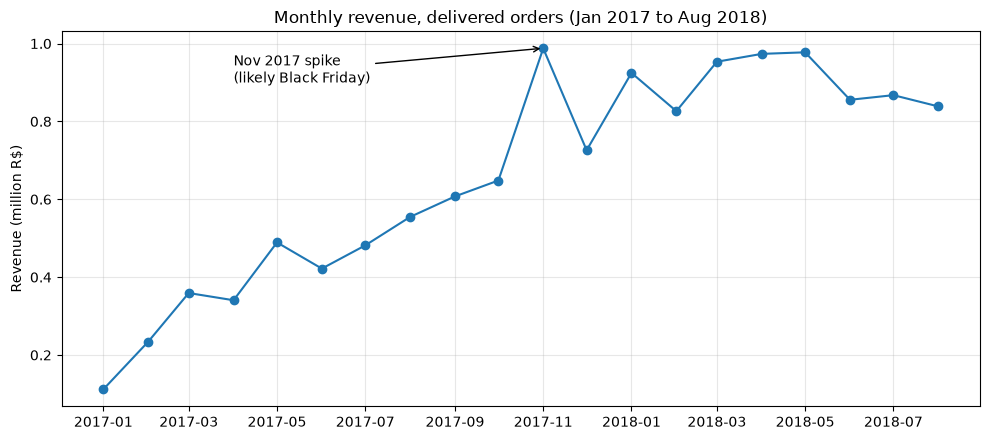

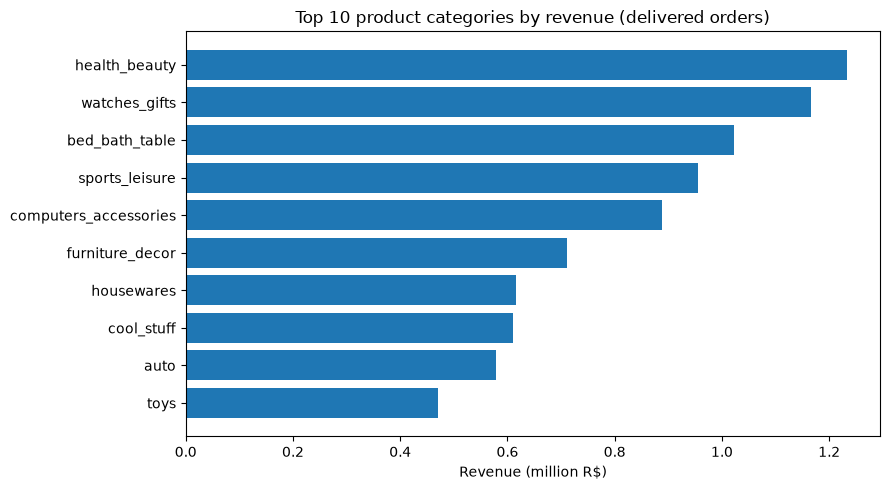

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

REPORTS = Path("C:/dev/projects/first-analysis/reports")

# --- Monthly revenue (full months only) ---
m = monthly.copy()
m["month"] = pd.to_datetime(m["month"])
m = m[(m["month"] >= "2017-01-01") & (m["month"] <= "2018-08-01")]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(m["month"], m["revenue"] / 1e6, marker="o")
ax.set_title("Monthly revenue, delivered orders (Jan 2017 to Aug 2018)")
ax.set_ylabel("Revenue (million R$)")
ax.grid(alpha=0.3)
ax.annotate("Nov 2017 spike\n(likely Black Friday)",
            xy=(pd.Timestamp("2017-11-01"), 0.988),
            xytext=(pd.Timestamp("2017-04-01"), 0.90),
            arrowprops={"arrowstyle": "->"})
plt.tight_layout()
plt.savefig(REPORTS / "monthly_revenue.png", dpi=150)
plt.show()

# --- Top 10 categories ---
t = top_categories.sort_values("revenue")

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(t["category"], t["revenue"] / 1e6)
ax.set_title("Top 10 product categories by revenue (delivered orders)")
ax.set_xlabel("Revenue (million R$)")
plt.tight_layout()
plt.savefig(REPORTS / "top_categories.png", dpi=150)
plt.show()

24 Nov revenue: R$149,917 vs typical 1-20 Nov day: R$22,652 (6.6x)


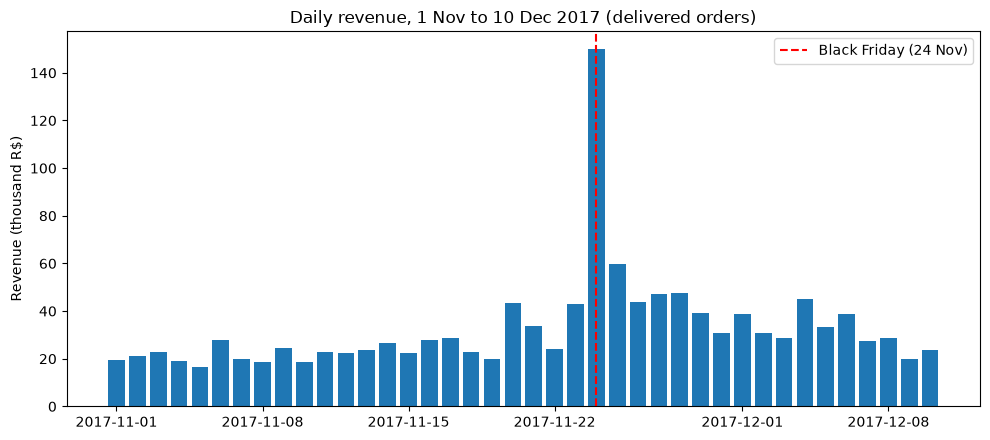

,day,revenue,orders
23,2017-11-24,149917.0,1147
24,2017-11-25,59929.0,487
27,2017-11-28,47577.0,371
26,2017-11-27,47237.0,395
33,2017-12-04,45101.0,322


In [10]:
daily = con.execute("""
    SELECT
        d.order_purchase_timestamp::DATE AS day,
        ROUND(SUM(oi.price), 0) AS revenue,
        COUNT(DISTINCT d.order_id) AS orders
    FROM order_items oi
    JOIN delivered_orders d ON d.order_id = oi.order_id
    WHERE d.order_purchase_timestamp >= '2017-11-01'
      AND d.order_purchase_timestamp <  '2017-12-11'
    GROUP BY 1
    ORDER BY 1
""").df()

daily["day"] = pd.to_datetime(daily["day"])

# How big is the spike compared with a typical early-November day?
bf = daily.loc[daily["day"] == pd.Timestamp("2017-11-24"), "revenue"].iloc[0]
baseline = daily.loc[daily["day"] <= pd.Timestamp("2017-11-20"), "revenue"].median()
print(f"24 Nov revenue: R${bf:,.0f} vs typical 1-20 Nov day: R${baseline:,.0f} ({bf/baseline:.1f}x)")

# Chart
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(daily["day"], daily["revenue"] / 1e3)
ax.axvline(pd.Timestamp("2017-11-24"), color="red", linestyle="--", label="Black Friday (24 Nov)")
ax.set_title("Daily revenue, 1 Nov to 10 Dec 2017 (delivered orders)")
ax.set_ylabel("Revenue (thousand R$)")
ax.legend()
plt.tight_layout()
plt.savefig(REPORTS / "black_friday_daily.png", dpi=150)
plt.show()

daily.sort_values("revenue", ascending=False).head(5)